# Roda.Motorku — Pemodelan Prediksi Harga Jual Motor Bekas

Notebook ini adalah **satu-satunya sumber resmi** untuk angka, tabel, dan gambar pada artikel
*"Rancang Bangun Website Katalog dan Prediksi Harga Jual Motor Bekas pada Showroom Roda.Motorku"*
(STAINS 2027), sekaligus sumber model yang dipakai aplikasi web.

| Bagian notebook | Bagian artikel |
|---|---|
| 1–2. Data & praproses | Metode — Pengumpulan dan Praproses Data, Tabel 1 |
| 3. Eksplorasi data | Hasil — pembahasan Tabel 2 |
| 4–5. Split 80:20, pelatihan, evaluasi | Metode — Pemodelan dan Evaluasi; Hasil — Tabel 2 |
| 6. Baseline & pengaruh `harga_beli` | Hasil — pembahasan Tabel 2 |
| 7. Gambar 2 & 3 | Hasil — Gambar 2 dan Gambar 3 |
| 8–9. Simpan model & ekspor ke web | Metode — Arsitektur sistem (Gambar 1, dibuat dengan `buat_gambar_arsitektur.py`) |

Konfigurasi tiga algoritma:

* **Linear Regression** — regresi linear dengan regularisasi L2 (*Ridge*, α = 1,0) agar koefisien
  stabil pada 34 kolom hasil *one-hot encoding* dengan hanya 149 data latih.
* **Decision Tree Regressor** — `max_depth=8`, `min_samples_split=4`.
* **Random Forest Regressor** — `n_estimators=150`, `max_features='sqrt'`.

Semua proses memakai `random_state=42` supaya hasilnya dapat direproduksi.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

# Gaya grafik: satu warna data, teks netral, grid tipis, tanpa judul di dalam
# gambar (judul ditulis di caption artikel).
WARNA_DATA = '#257de0'
WARNA_TEKS = '#191919'
WARNA_TEKS_2 = '#666666'
WARNA_GRID = '#e5e5e5'
WARNA_REFERENSI = '#8a8a8a'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.edgecolor': WARNA_TEKS_2, 'axes.labelcolor': WARNA_TEKS,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': WARNA_GRID, 'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'xtick.color': WARNA_TEKS_2, 'ytick.color': WARNA_TEKS_2,
    'legend.frameon': False,
})

def rupiah(x):
    return 'Rp ' + f'{x:,.0f}'.replace(',', '.')

def koma(x, d=4):
    return f'{x:.{d}f}'.replace('.', ',')

pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

## 1. Memuat dataset

In [2]:
df_mentah = pd.read_excel('dataset_motor_bekas_187-v2.xlsx')
print(f'Ukuran dataset awal: {df_mentah.shape[0]} baris x {df_mentah.shape[1]} kolom')
df_mentah.head()

Ukuran dataset awal: 187 baris x 11 kolom


,no,nama,merk_motor,tahun,kelengkapan_dokumen,kilometer,harga_beli,kondisi_mesin,domisili_samsat,cc,harga_jual
0,1,Smash,Suzuki,2002,bpkb,92400,1600000,Cukup,Nganjuk (AG),110,2100000
1,2,Mio Soul,Yamaha,2008,bpkb,76500,2200000,Cukup,Kediri Kota (AG),115,2700000
2,3,Supra X 125,Honda,2008,stnk bpkb,68200,7800000,Baik,Nganjuk (AG),125,8500000
3,4,Supra X 125 FI,Honda,2015,stnk bpkb,48900,10000000,Baik,Madiun (AE),125,10500000
4,5,Supra X 125,Honda,2008,stnk bpkb,59400,8500000,Sangat Baik,Tulungagung (AG),125,9000000


## 2. Praproses data

Nama kolom diseragamkan sesuai Tabel 1 artikel, lalu dicek duplikat, nilai kosong, dan tipe data.
Kolom `no` dan `nama` (tipe motor) hanya dipakai untuk katalog, tidak untuk pemodelan.

In [3]:
df = df_mentah.copy()
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
df = df.rename(columns={'merk_motor': 'merek'})

fitur_kategorikal = ['merek', 'kelengkapan_dokumen', 'kondisi_mesin', 'domisili_samsat']
fitur_numerik = ['tahun', 'kilometer', 'harga_beli', 'cc']
target = 'harga_jual'
fitur = fitur_kategorikal + fitur_numerik

print('Duplikat (tanpa kolom no):', df.drop(columns='no').duplicated().sum())
print('Nilai kosong per kolom:', df[fitur + [target]].isna().sum().to_dict())
df = df.drop_duplicates(subset=[c for c in df.columns if c != 'no']).dropna(subset=fitur + [target])
for c in fitur_numerik + [target]:
    df[c] = pd.to_numeric(df[c], errors='raise')
df = df.reset_index(drop=True)
print(f'Ukuran dataset bersih: {len(df)} baris')

for c in fitur_kategorikal:
    print(f'\n{c}:', df[c].value_counts().to_dict())

Duplikat (tanpa kolom no): 0
Nilai kosong per kolom: {'merek': 0, 'kelengkapan_dokumen': 0, 'kondisi_mesin': 0, 'domisili_samsat': 0, 'tahun': 0, 'kilometer': 0, 'harga_beli': 0, 'cc': 0, 'harga_jual': 0}
Ukuran dataset bersih: 187 baris

merek: {'Honda': 82, 'Yamaha': 57, 'Suzuki': 25, 'Vespa': 12, 'Kawasaki': 11}

kelengkapan_dokumen: {'stnk bpkb': 161, 'bpkb': 20, 'stnk': 6}

kondisi_mesin: {'Baik': 81, 'Sangat Baik': 76, 'Cukup': 25, 'Perlu Perbaikan': 5}

domisili_samsat: {'Nganjuk (AG)': 78, 'Kediri Kota (AG)': 15, 'Kediri Kabupaten (AG)': 13, 'Madiun (AE)': 10, 'Tulungagung (AG)': 9, 'Blitar (AG)': 8, 'Ponorogo (AE)': 8, 'Magetan (AE)': 7, 'Trenggalek (AG)': 7, 'Mojokerto (S)': 6, 'Sidoarjo (W)': 5, 'Ngawi (AE)': 5, 'Jombang (S)': 5, 'Surabaya (L)': 4, 'Pacitan (AE)': 2, 'Bojonegoro (S)': 2, 'Malang (N)': 2, 'Gresik (W)': 1}


## 3. Eksplorasi data

Grafik kiri menunjukkan sebaran harga jual. Grafik kanan menunjukkan hubungan `harga_beli`
dengan `harga_jual`, yang menjelaskan mengapa model linear bekerja sangat baik pada data ini.

Korelasi Pearson fitur numerik terhadap harga_jual:
harga_beli    0.9991
cc            0.6863
tahun         0.6672
kilometer    -0.6102

Margin showroom (harga_jual - harga_beli): rata-rata Rp 1.676.471, median Rp 1.500.000, rentang Rp 500.000 – Rp 4.000.000


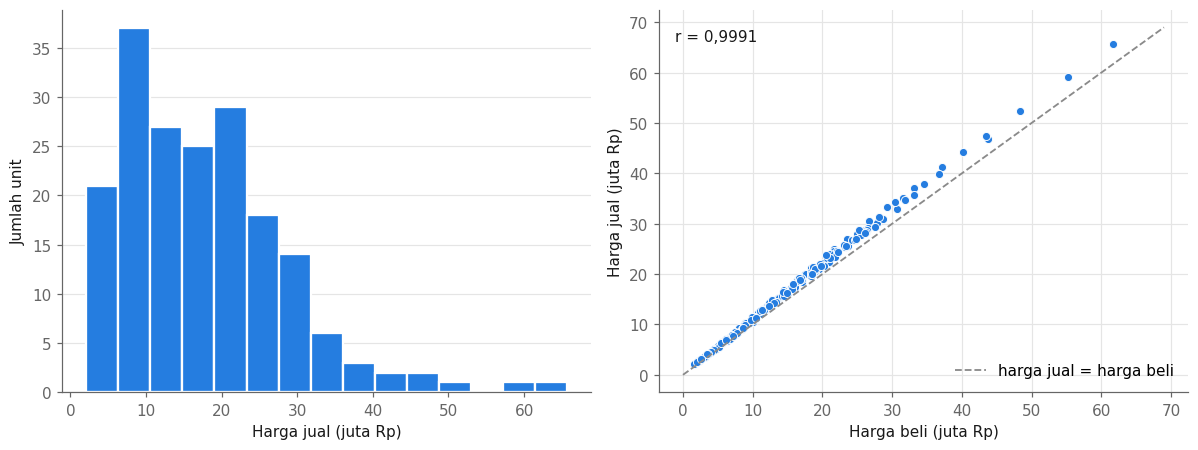

In [4]:
X = df[fitur].copy()
y = df[target].copy()

korelasi = df[fitur_numerik + [target]].corr()[target].drop(target).sort_values(ascending=False)
print('Korelasi Pearson fitur numerik terhadap harga_jual:')
print(korelasi.round(4).to_string())

margin = df[target] - df['harga_beli']
print(f'\nMargin showroom (harga_jual - harga_beli): rata-rata {rupiah(margin.mean())}, '
      f'median {rupiah(margin.median())}, rentang {rupiah(margin.min())} – {rupiah(margin.max())}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(df[target] / 1e6, bins=15, color=WARNA_DATA, edgecolor='white', linewidth=1.5)
axes[0].set_xlabel('Harga jual (juta Rp)')
axes[0].set_ylabel('Jumlah unit')
axes[0].grid(axis='x', visible=False)

axes[1].scatter(df['harga_beli'] / 1e6, df[target] / 1e6, s=28, color=WARNA_DATA,
                edgecolor='white', linewidth=0.6)
batas = [0, df[target].max() / 1e6 * 1.05]
axes[1].plot(batas, batas, ls='--', lw=1.2, color=WARNA_REFERENSI, label='harga jual = harga beli')
axes[1].set_xlabel('Harga beli (juta Rp)')
axes[1].set_ylabel('Harga jual (juta Rp)')
axes[1].text(0.03, 0.95, f"r = {koma(korelasi['harga_beli'])}", transform=axes[1].transAxes,
             va='top', color=WARNA_TEKS)
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/eda_distribusi_dan_harga_beli.png')
plt.show()

## 4. Pembagian data 80:20 dan pembuatan pipeline

* Fitur kategorikal: *One-Hot Encoding* (`handle_unknown='ignore'` agar input baru di web tidak error).
* Fitur numerik: *StandardScaler* hanya untuk Linear Regression (Ridge). Model pohon tidak
  dipengaruhi skala fitur, jadi Decision Tree dan Random Forest memakai nilai asli.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f'Data latih: {len(X_train)} unit (80%) | Data uji: {len(X_test)} unit (20%)')
print(f'Rata-rata harga jual data uji: {rupiah(y_test.mean())}')

def buat_preprocessor(kolom_numerik=fitur_numerik, skala=True):
    # Skala hanya dibutuhkan model linear; model pohon memakai nilai asli (hasilnya
    # setara, dan ambang pohon dapat dipakai langsung di web tanpa galat pembulatan).
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), fitur_kategorikal),
        ('num', StandardScaler() if skala else 'passthrough', kolom_numerik),
    ])

models = {
    'Linear Regression': Pipeline([
        ('preprocessor', buat_preprocessor()),
        ('regressor', Ridge(alpha=1.0)),
    ]),
    'Decision Tree Regressor': Pipeline([
        ('preprocessor', buat_preprocessor(skala=False)),
        ('regressor', DecisionTreeRegressor(max_depth=8, min_samples_split=4,
                                            random_state=RANDOM_STATE)),
    ]),
    'Random Forest Regressor': Pipeline([
        ('preprocessor', buat_preprocessor(skala=False)),
        ('regressor', RandomForestRegressor(n_estimators=150, max_features='sqrt',
                                            random_state=RANDOM_STATE)),
    ]),
}

Data latih: 149 unit (80%) | Data uji: 38 unit (20%)
Rata-rata harga jual data uji: Rp 17.355.263


## 5. Pelatihan dan evaluasi (Tabel 2)

Metrik pada data uji: MAE, RMSE, R², dan MAE relatif (MAE dibagi rata-rata harga jual data uji).
Kestabilan diukur dengan *5-fold cross-validation* pada seluruh 187 data (R² rata-rata ± simpangan baku).

In [6]:
hasil = []
prediksi = {}
for nama, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    prediksi[nama] = y_pred
    mae = mean_absolute_error(y_test, y_pred)
    cv = cross_val_score(pipe, X, y, cv=5, scoring='r2')
    hasil.append({
        'Model': nama,
        'MAE (Rp)': mae,
        'RMSE (Rp)': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred),
        'MAE Relatif (%)': mae / y_test.mean() * 100,
        'R2 CV (rata-rata)': cv.mean(),
        'R2 CV (SD)': cv.std(),
    })

df_hasil = pd.DataFrame(hasil).sort_values('MAE (Rp)').reset_index(drop=True)
df_hasil

,Model,MAE (Rp),RMSE (Rp),R2,MAE Relatif (%),R2 CV (rata-rata),R2 CV (SD)
0,Linear Regression,"549,924.4632","703,545.6578",0.9944,3.1686,0.9973,0.0010
1,Decision Tree Regressor,"594,517.5439","773,974.7510",0.9932,3.4256,0.9850,0.0072
2,Random Forest Regressor,"1,517,754.3860","2,076,189.4977",0.9508,8.7452,0.9019,0.0349


In [7]:
# Format Tabel 2 persis seperti di artikel
tabel_3_1 = pd.DataFrame({
    'Model': df_hasil['Model'],
    'MAE (Rp)': df_hasil['MAE (Rp)'].map(rupiah),
    'RMSE (Rp)': df_hasil['RMSE (Rp)'].map(rupiah),
    'R²': df_hasil['R2'].map(lambda v: f'{koma(v)} ({koma(v * 100, 2)}%)'),
    'MAE Relatif (%)': df_hasil['MAE Relatif (%)'].map(lambda v: f'{koma(v, 2)}%'),
    'R² CV (Rata-rata ± SD)': [f'{koma(m)} ± {koma(s)}'
                               for m, s in zip(df_hasil['R2 CV (rata-rata)'], df_hasil['R2 CV (SD)'])],
})
tabel_3_1

,Model,MAE (Rp),RMSE (Rp),R²,MAE Relatif (%),R² CV (Rata-rata ± SD)
0,Linear Regression,Rp 549.924,Rp 703.546,"0,9944 (99,44%)","3,17%","0,9973 ± 0,0010"
1,Decision Tree Regressor,Rp 594.518,Rp 773.975,"0,9932 (99,32%)","3,43%","0,9850 ± 0,0072"
2,Random Forest Regressor,Rp 1.517.754,Rp 2.076.189,"0,9508 (95,08%)","8,75%","0,9019 ± 0,0349"


## 6. Baseline dan pengaruh `harga_beli`

R² di atas 0,99 perlu dibandingkan dengan pembanding sederhana. *Baseline* di bawah ini tidak
memakai machine learning: harga jual = harga beli + median margin data latih. Selain itu, model
dilatih ulang **tanpa** `harga_beli` untuk melihat seberapa besar fitur lain menyumbang.

In [8]:
median_margin = (y_train - X_train['harga_beli']).median()
pred_baseline = X_test['harga_beli'] + median_margin
baris = [{
    'Skenario': f'Baseline: harga beli + median margin ({rupiah(median_margin)})',
    'MAE (Rp)': mean_absolute_error(y_test, pred_baseline),
    'R2': r2_score(y_test, pred_baseline),
}]

fitur_numerik_tanpa_hb = [c for c in fitur_numerik if c != 'harga_beli']
for nama, pipe in models.items():
    p = Pipeline([
        ('preprocessor', buat_preprocessor(fitur_numerik_tanpa_hb, skala=(nama == 'Linear Regression'))),
        ('regressor', pipe.named_steps['regressor'].__class__(**pipe.named_steps['regressor'].get_params())),
    ]).fit(X_train, y_train)
    pr = p.predict(X_test)
    baris.append({'Skenario': f'{nama} tanpa harga_beli',
                  'MAE (Rp)': mean_absolute_error(y_test, pr), 'R2': r2_score(y_test, pr)})

df_baseline = pd.DataFrame(baris)
df_baseline['MAE (Rp)'] = df_baseline['MAE (Rp)'].map(rupiah)
df_baseline

,Skenario,MAE (Rp),R2
0,Baseline: harga beli + median margin (Rp 1.500...,Rp 815.789,0.9874
1,Linear Regression tanpa harga_beli,Rp 4.018.360,0.7429
2,Decision Tree Regressor tanpa harga_beli,Rp 3.572.295,0.7641
3,Random Forest Regressor tanpa harga_beli,Rp 3.082.965,0.8056


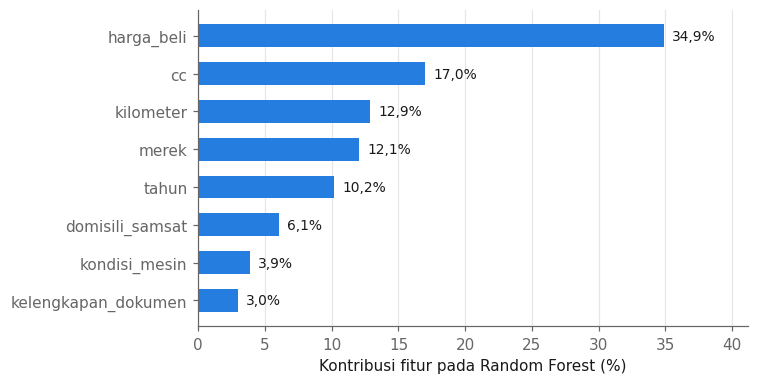

In [9]:
# Kontribusi tiap fitur pada Random Forest (dijumlahkan per fitur asli)
rf = models['Random Forest Regressor']
nama_kolom = rf.named_steps['preprocessor'].get_feature_names_out()
imp = pd.Series(rf.named_steps['regressor'].feature_importances_, index=nama_kolom)
imp_fitur = pd.Series({
    f: imp[[k for k in nama_kolom if k.split('__', 1)[1] == f or k.split('__', 1)[1].startswith(f + '_')]].sum()
    for f in fitur
}).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(imp_fitur.index, imp_fitur.values * 100, color=WARNA_DATA, height=0.6)
for i, v in enumerate(imp_fitur.values * 100):
    ax.text(v + 0.6, i, koma(v, 1) + '%', va='center', color=WARNA_TEKS, fontsize=9)
ax.set_xlabel('Kontribusi fitur pada Random Forest (%)')
ax.grid(axis='y', visible=False)
ax.set_xlim(0, imp_fitur.max() * 100 * 1.18)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/feature_importance_random_forest.png')
plt.show()

## 7. Gambar 2 dan Gambar 3 (model terbaik)

* **Gambar 2** — harga aktual vs harga prediksi. Titik yang makin dekat dengan garis y = x berarti
  prediksi makin tepat. Pita abu-abu adalah ± MAE.
* **Gambar 3** — residual (aktual − prediksi) terhadap harga prediksi. Grafik ini dipakai untuk
  melihat apakah kesalahan model bergantung pada besar kecilnya harga (bias sistematis).

Judul tidak ditaruh di dalam gambar karena sudah ada di caption artikel. File disimpan 300 dpi di `figures/`.

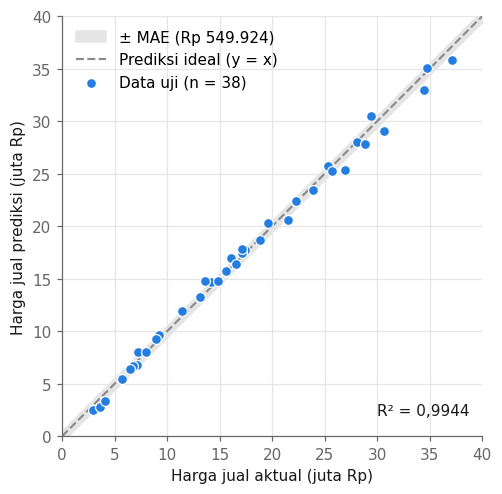

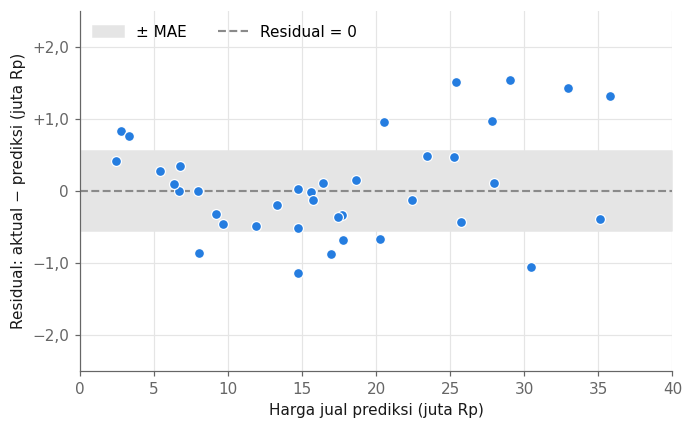

Model terbaik: Linear Regression
Rentang harga aktual data uji: Rp 2.900.000 – Rp 37.100.000
Residual: min -1,14 jt, maks 1,54 jt, rata-rata 0,075 jt
Persentase data uji dengan |residual| <= MAE: 63,2%
Korelasi residual vs prediksi: 0,229


In [10]:
nama_terbaik = df_hasil.iloc[0]['Model']
y_pred_best = prediksi[nama_terbaik]
mae_best = df_hasil.iloc[0]['MAE (Rp)']
aktual_jt = y_test.values / 1e6
pred_jt = y_pred_best / 1e6
residual_jt = aktual_jt - pred_jt

# Gambar 2
fig, ax = plt.subplots(figsize=(6.4, 4.6))
lo, hi = 0, np.ceil(max(aktual_jt.max(), pred_jt.max()) / 5) * 5
garis = np.array([lo, hi])
ax.fill_between(garis, garis - mae_best / 1e6, garis + mae_best / 1e6, color=WARNA_GRID,
                label=f'± MAE ({rupiah(mae_best)})')
ax.plot(garis, garis, ls='--', lw=1.4, color=WARNA_REFERENSI, label='Prediksi ideal (y = x)')
ax.scatter(aktual_jt, pred_jt, s=42, color=WARNA_DATA, edgecolor='white', linewidth=0.8,
           label=f'Data uji (n = {len(y_test)})', zorder=3)
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect('equal')
ax.set_xlabel('Harga jual aktual (juta Rp)')
ax.set_ylabel('Harga jual prediksi (juta Rp)')
ax.text(0.97, 0.05, f'R² = {koma(df_hasil.iloc[0]["R2"])}', transform=ax.transAxes,
        ha='right', color=WARNA_TEKS)
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/gambar_2_aktual_vs_prediksi.png')
plt.show()

# Gambar 3
fig, ax = plt.subplots(figsize=(6.4, 4.0))
x_lim = (0, hi)
ax.fill_between(x_lim, -mae_best / 1e6, mae_best / 1e6, color=WARNA_GRID, label='± MAE')
ax.axhline(0, ls='--', lw=1.4, color=WARNA_REFERENSI, label='Residual = 0')
ax.scatter(pred_jt, residual_jt, s=42, color=WARNA_DATA, edgecolor='white', linewidth=0.8, zorder=3)
ax.set_xlim(*x_lim)
r_max = np.ceil(np.abs(residual_jt).max() * 2) / 2 + 0.5
ax.set_ylim(-r_max, r_max)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(
    lambda v, _: '0' if abs(v) < 1e-9 else f'{v:+.1f}'.replace('.', ',').replace('-', '−')))
ax.set_xlabel('Harga jual prediksi (juta Rp)')
ax.set_ylabel('Residual: aktual − prediksi (juta Rp)')
ax.legend(loc='upper left', ncol=2)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/gambar_3_residual.png')
plt.show()

dalam_mae = np.mean(np.abs(residual_jt) <= mae_best / 1e6) * 100
print(f'Model terbaik: {nama_terbaik}')
print(f'Rentang harga aktual data uji: {rupiah(y_test.min())} – {rupiah(y_test.max())}')
print(f'Residual: min {koma(residual_jt.min(), 2)} jt, maks {koma(residual_jt.max(), 2)} jt, '
      f'rata-rata {koma(residual_jt.mean(), 3)} jt')
print(f'Persentase data uji dengan |residual| <= MAE: {koma(dalam_mae, 1)}%')
print(f'Korelasi residual vs prediksi: {koma(np.corrcoef(pred_jt, residual_jt)[0, 1], 3)}')

## 8. Simpan model terbaik (`.pkl`)

Model terbaik dipilih otomatis berdasarkan **MAE terendah** pada data uji. File `.pkl` berisi
pipeline lengkap (praproses + model) sehingga bisa langsung dipakai dengan `predict()` pada
DataFrame berisi 8 fitur.

In [11]:
baris_best = df_hasil.iloc[0]
pipeline_terbaik = models[nama_terbaik]
joblib.dump({
    'nama_model': nama_terbaik,
    'pipeline': pipeline_terbaik,
    'mae': float(baris_best['MAE (Rp)']),
    'rmse': float(baris_best['RMSE (Rp)']),
    'r2': float(baris_best['R2']),
    'cv_r2_mean': float(baris_best['R2 CV (rata-rata)']),
    'cv_r2_std': float(baris_best['R2 CV (SD)']),
    'fitur_masukan': fitur,
}, 'model_terbaik_roda_motorku.pkl')

# Cek ulang: muat kembali dan prediksi satu contoh
muat = joblib.load('model_terbaik_roda_motorku.pkl')
contoh = X_test.iloc[[0]]
print('Model tersimpan :', muat['nama_model'])
print('Contoh input    :', contoh.to_dict('records')[0])
print('Prediksi        :', rupiah(muat['pipeline'].predict(contoh)[0]), '| aktual:', rupiah(y_test.iloc[0]))

Model tersimpan : Linear Regression
Contoh input    : {'merek': 'Honda', 'kelengkapan_dokumen': 'stnk bpkb', 'kondisi_mesin': 'Baik', 'domisili_samsat': 'Nganjuk (AG)', 'tahun': 2014, 'kilometer': 111000, 'harga_beli': 8600000, 'cc': 125}
Prediksi        : Rp 9.657.050 | aktual: Rp 9.200.000


## 9. Ekspor parameter model ke aplikasi web

Aplikasi web (Next.js) menjalankan prediksi di `src/lib/mlEngine.ts` tanpa Python. Sel ini mengekspor
parameter **ketiga model yang sama persis** (koefisien Ridge, struktur Decision Tree, dan 150 pohon
Random Forest) ke `src/lib/trainedMlModels.json`. Dengan begitu metrik dan model terbaik di web
sama dengan Tabel 2.

Label `kelengkapan_dokumen` di dataset (`bpkb`, `stnk`, `stnk bpkb`) dipetakan ke label pada form
web. Sel terakhir memeriksa bahwa hasil ekspor memberi prediksi yang identik dengan scikit-learn.

In [12]:
LABEL_DOKUMEN_WEB = {'bpkb': 'Hanya BPKB', 'stnk': 'Hanya STNK', 'stnk bpkb': 'Lengkap (STNK + BPKB)'}
# Urutan fitur numerik di vektor web: [bias, harga_beli, tahun, kilometer, cc, one-hot...]
URUTAN_NUM_WEB = ['harga_beli', 'tahun', 'kilometer', 'cc']

def ambil(pipe):
    pre = pipe.named_steps['preprocessor']
    return pre.named_transformers_['cat'], pre.named_transformers_['num'], pipe.named_steps['regressor']

ohe, scaler, _ = ambil(models['Linear Regression'])
kategori = {f: list(c) for f, c in zip(fitur_kategorikal, ohe.categories_)}
n_oh = sum(len(c) for c in ohe.categories_)
mean_num = dict(zip(fitur_numerik, scaler.mean_))
scale_num = dict(zip(fitur_numerik, scaler.scale_))

# Indeks kolom sklearn -> indeks fitur web (tanpa bias)
peta_idx = {j: 4 + j for j in range(n_oh)}
for k, f in enumerate(fitur_numerik):
    peta_idx[n_oh + k] = URUTAN_NUM_WEB.index(f)

def ekspor_pohon(pohon):
    t = pohon.tree_
    def node(i):
        if t.children_left[i] == -1:
            return int(round(float(t.value[i][0][0])))
        j = int(t.feature[i])
        thr = float(t.threshold[i])  # model pohon dilatih pada nilai asli -> ambang dalam satuan asli
        return [peta_idx[j], round(thr, 3), node(t.children_left[i]), node(t.children_right[i])]
    return node(0)

ridge = ambil(models['Linear Regression'])[2]
coef = dict(zip(range(len(ridge.coef_)), ridge.coef_))
lr_weights = [float(ridge.intercept_)] + [float(coef[n_oh + fitur_numerik.index(f)]) for f in URUTAN_NUM_WEB] \
             + [float(coef[j]) for j in range(n_oh)]

ID = {'Linear Regression': 'lr', 'Decision Tree Regressor': 'dt', 'Random Forest Regressor': 'rf'}
metrics = {
    ID[r['Model']]: {
        'r2_score': round(float(r['R2']), 4), 'mae': int(round(r['MAE (Rp)'])),
        'rmse': int(round(r['RMSE (Rp)'])), 'mae_pct': round(float(r['MAE Relatif (%)']), 2),
        'cv_r2_mean': round(float(r['R2 CV (rata-rata)']), 4), 'cv_r2_std': round(float(r['R2 CV (SD)']), 4),
    } for _, r in df_hasil.iterrows()
}

bundle = {
    'source': 'notebooks/randomForest.ipynb',
    'dataset_size': int(len(df)), 'train_size': int(len(X_train)), 'test_size': int(len(X_test)),
    'split_ratio': '80:20',
    'best_model': ID[nama_terbaik],
    'tree_target': 'harga_jual',
    'cats': {
        'merek': kategori['merek'],
        'docs': [LABEL_DOKUMEN_WEB[v] for v in kategori['kelengkapan_dokumen']],
        'cond': kategori['kondisi_mesin'],
        'samsat': kategori['domisili_samsat'],
    },
    'means': [0.0] + [round(float(mean_num[f]), 6) for f in URUTAN_NUM_WEB],
    'stds': [1.0] + [round(float(scale_num[f]), 6) for f in URUTAN_NUM_WEB],
    'lr_weights': [round(w, 6) for w in lr_weights],
    'dt_tree': ekspor_pohon(models['Decision Tree Regressor'].named_steps['regressor']),
    'rf_trees': [ekspor_pohon(t) for t in models['Random Forest Regressor'].named_steps['regressor'].estimators_],
    'metrics': metrics,
    'feature_importances': {f: round(float(v) * 100, 1) for f, v in imp_fitur.sort_values(ascending=False).items()},
}
assert sorted(bundle['cats']['docs']) == bundle['cats']['docs'], 'urutan label dokumen harus sama dengan kategori sklearn'

path_web = os.path.join('..', 'src', 'lib', 'trainedMlModels.json')
with open(path_web, 'w', encoding='utf-8') as fh:
    json.dump(bundle, fh, separators=(',', ':'), ensure_ascii=False)
print(f'Tersimpan: {path_web} ({os.path.getsize(path_web) / 1024:,.0f} KB) | model terbaik: {nama_terbaik}')

Tersimpan: ..\src\lib\trainedMlModels.json (265 KB) | model terbaik: Linear Regression


In [13]:
# Verifikasi: tiru logika mlEngine.ts di Python dan bandingkan dengan scikit-learn
def vektor_web(row):
    v = [1.0] + [float(row[f]) for f in URUTAN_NUM_WEB]
    for f, kunci in [('merek', 'merek'), ('kelengkapan_dokumen', 'docs'), ('kondisi_mesin', 'cond'), ('domisili_samsat', 'samsat')]:
        nilai = LABEL_DOKUMEN_WEB[row[f]] if f == 'kelengkapan_dokumen' else row[f]
        v += [1.0 if nilai == c else 0.0 for c in bundle['cats'][kunci]]
    return v

def eval_pohon(node, x):
    while isinstance(node, list):
        node = node[2] if x[node[0]] <= node[1] else node[3]
    return node

selisih = {}
for nama, pipe in models.items():
    ref = pipe.predict(X_test)
    web = []
    for _, row in X_test.iterrows():
        v = vektor_web(row)
        if ID[nama] == 'lr':
            z = [(x - bundle['means'][i]) / bundle['stds'][i] if 1 <= i <= 4 else x for i, x in enumerate(v)]
            web.append(sum(a * b for a, b in zip(z, bundle['lr_weights'])))
        elif ID[nama] == 'dt':
            web.append(eval_pohon(bundle['dt_tree'], v[1:]))
        else:
            web.append(np.mean([eval_pohon(t, v[1:]) for t in bundle['rf_trees']]))
    selisih[nama] = float(np.max(np.abs(np.array(web) - ref)))
print('Selisih maksimum prediksi web vs scikit-learn (Rp):', {k: round(v, 2) for k, v in selisih.items()})
assert all(v < 1 for v in selisih.values())

Selisih maksimum prediksi web vs scikit-learn (Rp): {'Linear Regression': 0.05, 'Decision Tree Regressor': 0.33, 'Random Forest Regressor': 0.0}
